# 1. Image Formation

Practice for module 1: perspective projection and vanishing points, the thin lens equation, blur circles
and depth of field (including its asymmetry), radial distortion and its correction, and the focal length of
two thin lenses.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80

## 1.1 Perspective projection

A scene point `(X, Y, Z)` lands on the image plane at `(f·X/Z, f·Y/Z)`. The same cube placed farther away
looks smaller (magnification `f / Z`), and the parallel edges of a long corridor converge to a vanishing point.

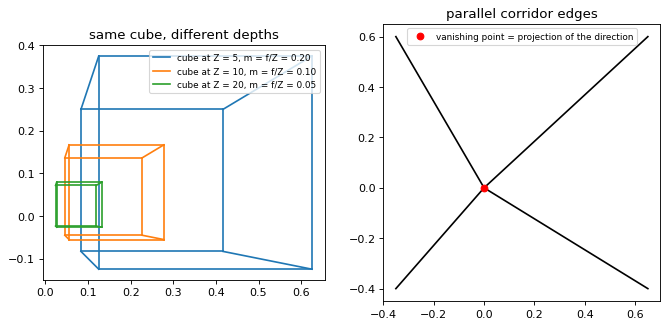

In [2]:
def project(P, f=1.0):
    return f * P[:, :2] / P[:, 2:3]

cube = np.array([[x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (-1, 1)], float)
edges = [(i, j) for i in range(8) for j in range(i + 1, 8) if np.sum(cube[i] != cube[j]) == 1]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for Z, c in [(5, "tab:blue"), (10, "tab:orange"), (20, "tab:green")]:
    p = project(cube + [1.5, 0.5, Z])
    for i, j in edges: axes[0].plot(*p[[i, j]].T, color=c)
    axes[0].plot([], [], color=c, label=f"cube at Z = {Z}, m = f/Z = {1 / Z:.2f}")
axes[0].set_aspect("equal"); axes[0].legend(fontsize=8); axes[0].set_title("same cube, different depths")

for x in (-1, 1):
    for y in (-1, 1):
        line = np.array([[x, y, z] for z in np.linspace(2, 200, 100)])
        axes[1].plot(*project(line + [0.3, 0.2, 0]).T, "k")
d = np.array([[0, 0, 1.0]])
vp = project(d + 0)                      # direction (0, 0, 1) projects to (0, 0) for lines through any point
axes[1].plot(*vp.T, "ro", label="vanishing point = projection of the direction")
axes[1].set_aspect("equal"); axes[1].legend(fontsize=8); axes[1].set_title("parallel corridor edges")
plt.show()

## 1.2 Thin lens, blur circle and depth of field

Thin lens: `1/f = 1/i + 1/o`. A point at depth `o` is focused at `i`; if the sensor sits at `i_f` (focused
on `o_f`), the point spreads into a blur circle of diameter `b = D·|i − i_f| / i`, where `D` is the aperture.
Depth of field is the depth range where `b` stays under one pixel.

f/1.8 : in focus from 1.986 m to 2.014 m (in front 0.014 m, behind 0.014 m)
f/4   : in focus from 1.969 m to 2.032 m (in front 0.031 m, behind 0.032 m)
f/11  : in focus from 1.918 m to 2.090 m (in front 0.082 m, behind 0.090 m)


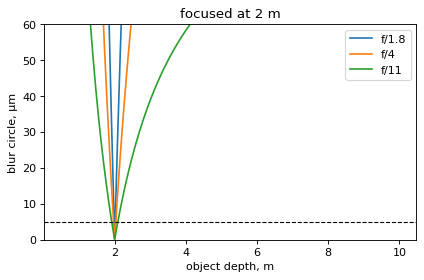

In [3]:
f = 0.050                 # 50 mm lens
o_f = 2.0                 # focused at 2 m
pixel = 5e-6              # 5 µm pixels
img_dist = lambda o: 1 / (1 / f - 1 / o)
i_f = img_dist(o_f)

def blur(o, N):
    D = f / N             # f-number N = f / D
    return D * np.abs(img_dist(o) - i_f) / img_dist(o)

o = np.linspace(0.5, 10, 2000)
fine = np.linspace(1.5, 3.0, 300001)
plt.figure(figsize=(6, 3.5))
for N in [1.8, 4, 11]:
    b = blur(o, N)
    ok = fine[blur(fine, N) <= pixel]
    plt.plot(o, b * 1e6, label=f"f/{N}")
    print(f"f/{N:<4}: in focus from {ok.min():.3f} m to {ok.max():.3f} m "
          f"(in front {o_f - ok.min():.3f} m, behind {ok.max() - o_f:.3f} m)")
plt.axhline(pixel * 1e6, color="k", ls="--", lw=1); plt.ylim(0, 60)
plt.xlabel("object depth, m"); plt.ylabel("blur circle, µm"); plt.legend(); plt.title("focused at 2 m")
plt.show()

Smaller apertures (larger f-number) give a deeper depth of field, and the in-focus range always extends
farther behind the focus plane than in front of it.

## 1.3 Radial distortion

A common model: `r_d = r (1 + k1 r² + k2 r⁴)`. `k1 < 0` gives barrel distortion, `k1 > 0` pincushion. With a
known model the distortion is undone by inverting it (here with a few fixed-point iterations).

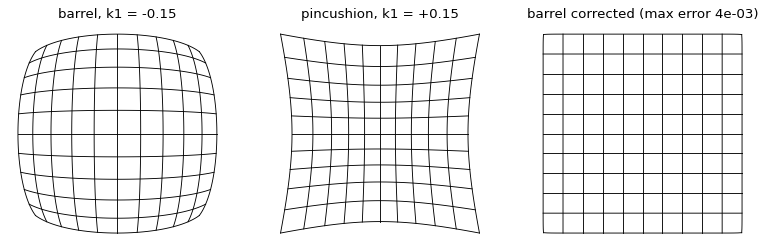

In [4]:
g = np.linspace(-1, 1, 11)
grid = [np.c_[np.full(50, v), np.linspace(-1, 1, 50)] for v in g] + [np.c_[np.linspace(-1, 1, 50), np.full(50, v)] for v in g]

def distort(p, k1, k2=0.0):
    r2 = (p ** 2).sum(1, keepdims=True)
    return p * (1 + k1 * r2 + k2 * r2 ** 2)

def undistort(pd, k1, k2=0.0, iters=20):
    p = pd.copy()
    for _ in range(iters):
        r2 = (p ** 2).sum(1, keepdims=True)
        p = pd / (1 + k1 * r2 + k2 * r2 ** 2)
    return p

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, k1, t in [(axes[0], -0.15, "barrel, k1 = -0.15"), (axes[1], 0.15, "pincushion, k1 = +0.15")]:
    for line in grid: ax.plot(*distort(line, k1).T, "k", lw=0.8)
    ax.set_aspect("equal"); ax.set_title(t); ax.axis("off")
err = max(np.abs(undistort(distort(l, -0.15), -0.15) - l).max() for l in grid)
for line in grid: axes[2].plot(*undistort(distort(line, -0.15), -0.15).T, "k", lw=0.8)
axes[2].set_aspect("equal"); axes[2].set_title(f"barrel corrected (max error {err:.0e})"); axes[2].axis("off")
plt.show()

## 1.4 Two thin lenses

Trace a ray parallel to the axis through two thin lenses separated by `d` (paraxial ray transfer
matrices) and read off the effective focal length; it matches `1/f = 1/f1 + 1/f2 − d/(f1 f2)`.

In [5]:
lens = lambda f: np.array([[1, 0], [-1 / f, 1]])
gap = lambda d: np.array([[1, d], [0, 1]])
for f1, f2, d in [(0.1, 0.1, 0.0), (0.1, 0.05, 0.02), (0.2, -0.1, 0.05)]:
    M = lens(f2) @ gap(d) @ lens(f1)
    print(f"f1 = {f1}, f2 = {f2}, d = {d}: from ray tracing f = {-1 / M[1, 0]:.4f}, "
          f"formula f = {1 / (1 / f1 + 1 / f2 - d / (f1 * f2)):.4f}")

f1 = 0.1, f2 = 0.1, d = 0.0: from ray tracing f = 0.0500, formula f = 0.0500
f1 = 0.1, f2 = 0.05, d = 0.02: from ray tracing f = 0.0385, formula f = 0.0385
f1 = 0.2, f2 = -0.1, d = 0.05: from ray tracing f = -0.4000, formula f = -0.4000
